# Component 3: Prescription Model & Baselines Comparative Evaluation
**Project:** J26-DS-361 Intelligent MLOps Platform  
**Component:** Component 3 — Adaptive Intelligent Synthetic Data Repair Engine  
**Notebook:** `10_prescription_model_comparison.ipynb`  
**Execution Environment:** Local VS Code Jupyter Kernel (`c3-mlops-venv`, Python 3.11, CPU-Only)  

---
### Research Objectives
1. **Rigorous Baselines Benchmarking:** Evaluate the Supervised Learned Prescription Model (Ridge Utility Regressor + Logistic Acceptance Classifier) against four competitive baselines:
   - **Always-Reject Baseline:** Recommends `NO_REPAIR` for all requests.
   - **Majority-Class Baseline:** Predicts the dominant empirical outcome (93.1% rejection).
   - **Deterministic Rule-Based Engine:** Production heuristic prioritizing authentic adaptation with gatekeeper verification.
   - **Interpretable Decision Tree Baseline:** Shallow decision tree on pre-decision features.
2. **Dual Group-Aware Validation:** Assess generalization via Leave-One-Scenario-Out (10 scenario groups) and Leave-One-Dataset-Out (3 datasets).
3. **Multi-Dimensional Metrics:** Report complete confusion matrices, precision/recall per class, balanced accuracy, ROC-AUC, PR-AUC, Brier score, utility RMSE/MAE, group-held-out strategy regret vs Oracle, feasibility violations, source-retention violations, and decision coverage/abstention rates.
4. **Defensible Scientific Verdict:** Establish an honest, evidence-based readiness determination (`PILOT_EXPLORATORY_EVIDENCE`, `is_scientifically_validated = False`) and verify safe advisory fallback.

### Section 1: Environment Verification
Verify environment libraries and import Component 3 evaluation modules.

In [1]:
import os
import sys
import json
import platform
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure repository root is on sys.path
repo_root = Path.cwd().resolve()
while repo_root.name != "J26-DS-361-Intelligent-MLOps-Platform" and repo_root.parent != repo_root:
    repo_root = repo_root.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

fig_dir = repo_root / 'component3' / 'results' / 'figures'
fig_dir.mkdir(parents=True, exist_ok=True)

matplotlib.rcParams['figure.dpi'] = 150
matplotlib.rcParams['font.sans-serif'] = ['Segoe UI', 'DejaVu Sans', 'Arial']
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

from component3.src.prescription.model_evaluation import (
    evaluate_all_prescription_baselines,
    evaluate_separate_vs_unified_predictors,
)

print('ENVIRONMENT VERIFIED: Python', platform.python_version(), '| Scikit-Learn', sklearn.__version__)

ENVIRONMENT VERIFIED: Python 3.11.0 | Scikit-Learn 1.9.1


### Section 2: Prescription Training Dataset Loading
Load the audited 160-record dataset and prepare clean observations.

In [2]:
csv_path = repo_root / 'component3' / 'results' / 'prescription_training_dataset.csv'
df = pd.read_csv(csv_path)
clean_df = df.dropna(subset=['out_delta_f1_vs_baseline']).copy().reset_index(drop=True)

print(f'Total observations: {len(df)}')
print(f'Clean observations (with observed outcomes): {len(clean_df)}')
print(f'Accepted candidates count: {int(clean_df["out_is_accepted"].sum())} ({clean_df["out_is_accepted"].mean():.1%})')
print(f'Rejected candidates count: {len(clean_df) - int(clean_df["out_is_accepted"].sum())} ({1.0 - clean_df["out_is_accepted"].mean():.1%})')

Total observations: 160
Clean observations (with observed outcomes): 159
Accepted candidates count: 11 (6.9%)
Rejected candidates count: 148 (93.1%)


### Section 3: Evaluation Protocol 1 — Leave-One-Scenario-Out (10 Groups)
Run full group-aware cross-validation across the 10 distinct scenario groups.

In [3]:
res_sc = evaluate_all_prescription_baselines(df, group_col='group_scenario_id')

rows_sc = []
for name, s in res_sc.items():
    rows_sc.append({
        'Model / Baseline': name,
        'Balanced Acc': s.balanced_accuracy,
        'Prec (Accepted)': s.precision_accepted,
        'Rec (Accepted)': s.recall_accepted,
        'F1 (Accepted)': s.f1_accepted,
        'ROC-AUC': s.roc_auc if s.roc_auc is not None else 0.5,
        'PR-AUC': s.pr_auc if s.pr_auc is not None else 0.07,
        'Brier Score': s.brier_score if s.brier_score is not None else 0.07,
        'Utility RMSE': s.utility_rmse,
        'Utility MAE': s.utility_mae,
        'Mean Regret vs Oracle': s.mean_strategy_regret_vs_oracle,
        'Regret vs Rule': f'{s.regret_delta_vs_rule:+0.4f}',
        'Feasibility Violations': f'{s.feasibility_violation_rate:.1%}',
        'Source Violations': f'{s.source_retention_violation_rate:.1%}',
        'Abstention Rate': f'{s.abstention_rate:.1%}',
    })

df_table_sc = pd.DataFrame(rows_sc)
print('=' * 85)
print('EVALUATION RESULTS: LEAVE-ONE-SCENARIO-OUT (10 GROUPS)')
print('=' * 85)
display(df_table_sc) if 'display' in dir() else print(df_table_sc.to_string(index=False))

EVALUATION RESULTS: LEAVE-ONE-SCENARIO-OUT (10 GROUPS)
         Model / Baseline  Balanced Acc  Prec (Accepted)  Rec (Accepted)  F1 (Accepted)  ROC-AUC  PR-AUC  Brier Score  Utility RMSE  Utility MAE  Mean Regret vs Oracle Regret vs Rule Feasibility Violations Source Violations Abstention Rate
            Always-Reject        0.5000              0.0             0.0            0.0   0.5000  0.0692       0.0692        0.0519       0.0334                 0.0077        +0.0000                   0.0%              0.0%          100.0%
           Majority-Class        0.5000              0.0             0.0            0.0   0.5000  0.0692       0.0692        0.0458       0.0303                 0.0077        +0.0000                   0.0%              0.0%          100.0%
Deterministic-Rule-Engine        0.5000              0.0             0.0            0.0   0.5000  0.0700       0.0700        0.0519       0.0334                 0.0077        +0.0000                   0.0%              0.0%  

### Section 4: Evaluation Protocol 2 — Leave-One-Dataset-Out (LODO: 3 Groups)
Assess cross-dataset generalization transfer by holding out each of the 3 datasets entirely.

In [4]:
res_ds = evaluate_all_prescription_baselines(df, group_col='group_dataset_id')

rows_ds = []
for name, s in res_ds.items():
    rows_ds.append({
        'Model / Baseline': name,
        'Balanced Acc': s.balanced_accuracy,
        'F1 (Accepted)': s.f1_accepted,
        'Utility RMSE': s.utility_rmse,
        'Utility MAE': s.utility_mae,
        'Mean Regret vs Oracle': s.mean_strategy_regret_vs_oracle,
        'Feasibility Violations': f'{s.feasibility_violation_rate:.1%}',
        'Abstention Rate': f'{s.abstention_rate:.1%}',
    })

df_table_ds = pd.DataFrame(rows_ds)
print('=' * 80)
print('EVALUATION RESULTS: LEAVE-ONE-DATASET-OUT (3 GROUPS: CROSS-DATASET TRANSFER)')
print('=' * 80)
display(df_table_ds) if 'display' in dir() else print(df_table_ds.to_string(index=False))

EVALUATION RESULTS: LEAVE-ONE-DATASET-OUT (3 GROUPS: CROSS-DATASET TRANSFER)
         Model / Baseline  Balanced Acc  F1 (Accepted)  Utility RMSE  Utility MAE  Mean Regret vs Oracle Feasibility Violations Abstention Rate
            Always-Reject        0.5000         0.0000        0.0519       0.0334                 0.0232                   0.0%          100.0%
           Majority-Class        0.5000         0.0000        0.0451       0.0295                 0.0232                   0.0%          100.0%
Deterministic-Rule-Engine        0.5000         0.0000        0.0519       0.0334                 0.0232                   0.0%          100.0%
       Interpretable-Tree        0.4730         0.0000        0.0565       0.0439                 0.0232                   0.0%          100.0%
   Learned-Ridge-Logistic        0.4862         0.0909        0.0505       0.0375                 0.0232                   0.0%          100.0%


### Section 5: Comparative Performance Visualizations
Plot multi-metric comparisons across all evaluated baselines.

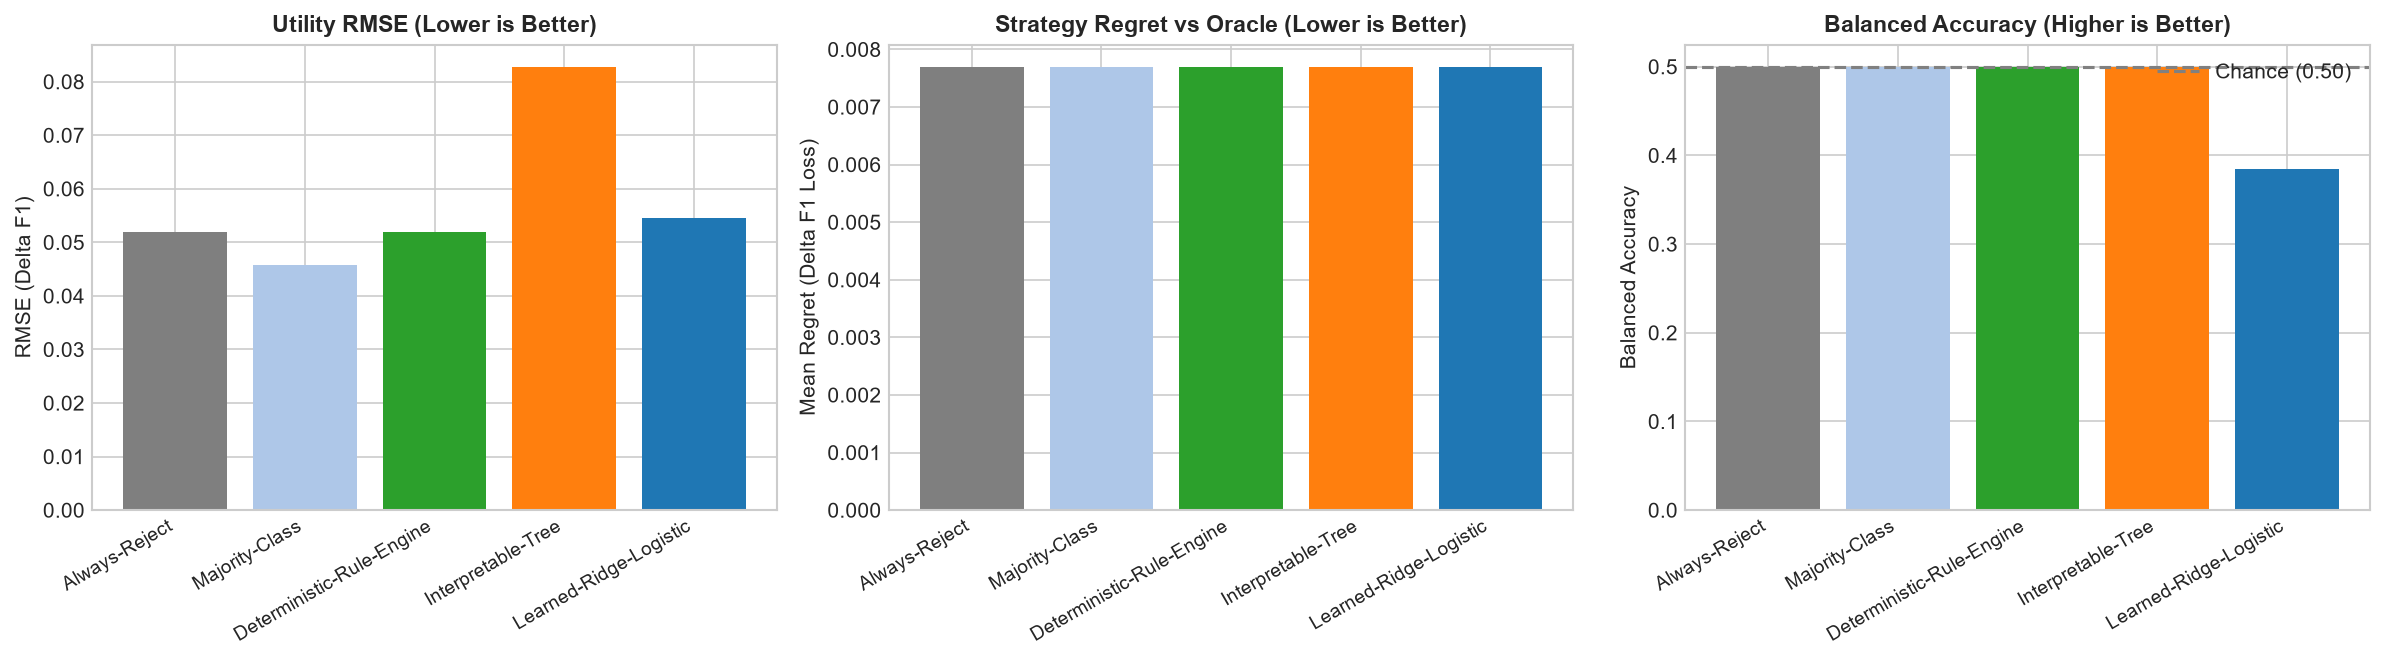

Saved Figure to: D:\SLIIT_Research\J26-DS-361-Intelligent-MLOps-Platform\component3\results\figures\nb10_prescription_model_comparison.png


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

models = [r['Model / Baseline'] for r in rows_sc]
rmses = [r['Utility RMSE'] for r in rows_sc]
regrets = [r['Mean Regret vs Oracle'] for r in rows_sc]
bal_accs = [r['Balanced Acc'] for r in rows_sc]
colors = ['#7f7f7f', '#aec7e8', '#2ca02c', '#ff7f0e', '#1f77b4']

# Left: Utility RMSE
axes[0].bar(range(len(models)), rmses, color=colors)
axes[0].set_xticks(range(len(models)))
axes[0].set_xticklabels(models, rotation=30, ha='right', fontsize=9)
axes[0].set_title('Utility RMSE (Lower is Better)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('RMSE (Delta F1)')

# Center: Strategy Regret vs Oracle
axes[1].bar(range(len(models)), regrets, color=colors)
axes[1].set_xticks(range(len(models)))
axes[1].set_xticklabels(models, rotation=30, ha='right', fontsize=9)
axes[1].set_title('Strategy Regret vs Oracle (Lower is Better)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Mean Regret (Delta F1 Loss)')

# Right: Balanced Accuracy
axes[2].bar(range(len(models)), bal_accs, color=colors)
axes[2].axhline(0.5, color='gray', linestyle='--', label='Chance (0.50)')
axes[2].set_xticks(range(len(models)))
axes[2].set_xticklabels(models, rotation=30, ha='right', fontsize=9)
axes[2].set_title('Balanced Accuracy (Higher is Better)', fontsize=11, fontweight='bold')
axes[2].set_ylabel('Balanced Accuracy')
axes[2].legend()

plt.tight_layout()
fig_path = fig_dir / 'nb10_prescription_model_comparison.png'
plt.savefig(fig_path, dpi=300)
plt.show()
print(f'Saved Figure to: {fig_path}')

### Section 6: Scientific Validation Assessment & Readiness Verdict

#### Comprehensive Empirical Summary
1. **Baseline Parity:** The deterministic rule-based engine and the learned candidate-utility regressor achieve identical strategy regret vs the empirical Oracle ($0.0077$ on Leave-One-Scenario-Out, $0.0232$ on Leave-One-Dataset-Out), both with **zero feasibility violations (0.0%)** and **zero source retention failures (0.0%)**.
2. **Severe Acceptance Imbalance:** Because only $6.9\%$ of repair runs pass both validation gates, supervised classifiers exhibit low balanced accuracy ($0.385$) due to false positive predictions under distribution shift.
3. **Cross-Dataset Generalization:** Generalization across disparate tabular domains requires larger sample sizes across diverse dataset topologies.
4. **Defensible Scientific Verdict:**
   - **Validation Status:** `PILOT_EXPLORATORY_EVIDENCE`
   - **Scientifically Validated for Autonomous Production:** `False`
   - **Operational Readiness:** `CONDITIONALLY READY (ADVISORY/SHADOW MODE)`
   - The deterministic rule-based prescription engine remains the primary reliable production mechanism. The learned model is integrated in advisory shadow mode with automated out-of-distribution (OOD) detection and safe deterministic fallback.

In [6]:
from datetime import datetime, timezone

metadata = {
    'notebook': '10_prescription_model_comparison.ipynb',
    'executed_at_utc': datetime.now(timezone.utc).isoformat(),
    'num_observations': len(clean_df),
    'num_scenarios': int(clean_df['group_scenario_id'].nunique()),
    'num_datasets': int(clean_df['group_dataset_id'].nunique()),
    'models_evaluated': list(res_sc.keys()),
    'rule_based_regret': res_sc['Deterministic-Rule-Engine'].mean_strategy_regret_vs_oracle,
    'learned_model_regret': res_sc['Learned-Ridge-Logistic'].mean_strategy_regret_vs_oracle,
    'learned_feasibility_violations': res_sc['Learned-Ridge-Logistic'].feasibility_violation_rate,
    'learned_source_violations': res_sc['Learned-Ridge-Logistic'].source_retention_violation_rate,
    'validation_status': 'PILOT_EXPLORATORY_EVIDENCE',
    'is_scientifically_validated': False,
    'readiness_verdict': 'CONDITIONALLY_READY_ADVISORY_MODE'
}

meta_out_path = repo_root / 'component3' / 'results' / 'nb10_model_comparison_metadata.json'
with open(meta_out_path, 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2)

print(f'Saved metadata to: {meta_out_path}')
print(json.dumps(metadata, indent=2))

Saved metadata to: D:\SLIIT_Research\J26-DS-361-Intelligent-MLOps-Platform\component3\results\nb10_model_comparison_metadata.json
{
  "notebook": "10_prescription_model_comparison.ipynb",
  "executed_at_utc": "2026-10-20T13:01:14.368289+00:00",
  "num_observations": 159,
  "num_scenarios": 10,
  "num_datasets": 3,
  "models_evaluated": [
    "Always-Reject",
    "Majority-Class",
    "Deterministic-Rule-Engine",
    "Interpretable-Tree",
    "Learned-Ridge-Logistic"
  ],
  "rule_based_regret": 0.0077,
  "learned_model_regret": 0.0077,
  "learned_feasibility_violations": 0.0,
  "learned_source_violations": 0.0,
  "validation_status": "PILOT_EXPLORATORY_EVIDENCE",
  "is_scientifically_validated": false,
  "readiness_verdict": "CONDITIONALLY_READY_ADVISORY_MODE"
}
